# **Maestría en Inteligencia Artificial Aplicada**

## **Curso: Inteligencia Artificial y Aprendizaje Automático**

**Tecnológico de Monterrey**

**Prof Luis Eduardo Falcón Morales**

### **Actividad de Modelos basados en Árboles**

* **Nombre:** Adrián Aguilar Sánchez

* **Matrícula:** A01651592

# **Introducción: Auditoría de modelos de riesgo crediticio basados en Árboles**



### **Contexto del problema:**

* Una startup de tecnología financiera (fintech) llamada CrediNova busca fortalecer su proceso de evaluación de riesgo para créditos de consumo. Actualmente, la empresa recibe miles de solicitudes cada mes y desea anticipar cuáles clientes podrían incumplir sus obligaciones financieras durante los próximos 90 días.

* Dichos clientes ya tienen una relación vigente con la institución, con la cual ya poseen uno o más productos financieros activos. Se desea predecir, al momento de la evaluación (para otorgar o revisar un crédito), cuáles de dichos clientes caerán en incumplimiento de algunos de sus pagos durante los siguientes 90 días.

* Un analista junior del área de ciencia de datos bajo su propia iniciativa desarrolló la solución que se encuentra en este cuaderno de Jupyter, la cual está basada en modelos de árboles. Se dio a la tarea de conjuntar la información histórica con diversas áreas de la empresa y generar la base de datos que se encuentra en el archivo "fintech_default_risk.csv". Dicho archivo lo encuentras en Canvas.  

* Los resultados que se obtienen al ejecutar el código se ven bastante prometedores, tan es así, que el CEO desea autorizar su despliegue a producción lo antes posible. Sin embargo, la dirección de riesgos desea realizar antes una última validación de la propuesta. Siendo tú un científico de datos senior, te encargan realizar una auditoría forense de este cuaderno.  

* En particular, se espera que cumplas con los siguientes objetivos:

  * Puedes modificar el cuaderno (celdas de texto y código) tanto como lo consideres necesario, salvo donde se te indique.

  * Identificar y documentar al menos 6 errores conceptuales o metodológicos en la propuesta actual.
  
  * Detectar posibles fuentes de fuga de información (data leakage) tanto en los datos como en el proceso de ajuste y entrenamiento de los modelos.

  * Justificar el uso de la métrica, y en su caso, evaluar la pertinencia de proponer y usar otras métricas.

  * Identificar evidencia de sub o sobreentrenamiento con respecto a la métrica en cuestión.

  * Analizar el impacto de la selección del umbral de clasificación sobre los resultados del negocio.

  * Decidir cuál de los 3 modelos de árboles consideras el más adecuado para desplegar en producción.

  * Identificar los 3 o 4 factores más importantes del mejor modelo obtenido. Explicar sus significados en el contexto de negocio.

  * Realizar un reporte del resultado de la auditoría forense comprensible para los tomadores de decisiones. En particular, indicar si el modelo se puede desplegar en producción como lo propone el analista junior, o cuál serían en dado caso las recomendaciones.

  * Reportar las herramientas de IA generativa (LLMs) utilizadas como apoyo para la auditoría.
  

### **Descripción del negocio:**

* Cada vez que una solicitud de crédito es aprobada:
   * Si el cliente paga correctamente, la empresa obtiene una utilidad neta estimada de $100 USD.

   * Si el cliente entra en incumplimiento, la empresa enfrenta una pérdida promedio estimada de $500 USD.

* Por este motivo, el objetivo no consiste únicamente en maximizar métricas estadísticas, sino en maximizar el valor económico esperado para la organización. Por ello, como parte del análisis, también deberás estimar:
   * La utilidad esperada utilizando el umbral estándar de clasificación (0.5).

   * La utilidad esperada utilizando un umbral optimizado.
   
   * El impacto económico estimado por cada 10,000 solicitudes evaluadas.

# **Cargando y conociendo la información**

In [101]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import (
    accuracy_score, roc_auc_score, average_precision_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    roc_curve, precision_recall_curve, brier_score_loss
)
from imblearn.over_sampling import SMOTE

from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
import shap


RANDOM_STATE = 11   # No modificar el valor de esta semilla.
                    # Siempre que aparezca esta semilla, seguirla utilizando,
                    # inclusive con modelos o cualquier otra función o método.

In [102]:
# Cargamos los datos y obtenemos alguna información básica:

df = pd.read_csv('/content/fintech_default_risk.csv')

print("Dimensión:", df.shape)
print("-"*25)
print('Variables involucradas:')
print(df.head(3).T)

print("\n")
print("-"*25)
print("Distribución objetivo:")
print(df["default_90d"].value_counts(normalize=True))


Dimensión: (5000, 14)
-------------------------
Variables involucradas:
                                         0             1             2
edad                             46.000000     37.000000     48.000000
ingreso_mensual               34959.928315   8659.826698  11502.487602
antiguedad_laboral_meses        296.000000      6.000000    166.000000
score_crediticio                659.093869    728.456721    636.261824
utilizacion_credito               0.410414      0.882132      0.408709
atrasos_12m                       3.000000      1.000000      1.000000
consultas_buro_6m                 5.000000      2.000000      3.000000
num_productos                     7.000000      3.000000      1.000000
limite_credito               209105.311645  44070.504292  42132.236007
deuda_total                   77661.271706  42105.837892  15409.496357
relacion_deuda_ingreso            2.221373      4.861642      1.339550
dias_max_atraso_30d_despues       7.000000      4.000000      3.000000
clien

In [103]:
# Definimos nuestras variables de entrada y la objetivo:

target = "default_90d"

X = df.drop(columns=[target])
y = df[target]

In [104]:
# Debido al desbalanceo de clases, aplicaremos una técnica de balanceo de clases.

smote = SMOTE(random_state=RANDOM_STATE   # semilla
              )

X_res, y_res = smote.fit_resample(X, y) # Balanceamos las clases con valores predeterminados de SMOTE.

X_train, X_test, y_train, y_test = train_test_split(
    X_res,
    y_res,
    test_size=0.30,  # Usemos una partición 70%-30%, pero podría ajustarse, en dado caso.
    random_state=RANDOM_STATE  # semilla
)

# Propuesta del Analista Junior

## **Configuración y Entrenamiento de los Modelos**

In [105]:
# --- Modelo 1: Árbol de decisión ---
dt = DecisionTreeClassifier(random_state=RANDOM_STATE  # semilla
                            )
dt.fit(X_train, y_train)

# --- Modelo 2: Random Forest ---
rf = RandomForestClassifier(random_state=RANDOM_STATE  # semilla
                            )
rf.fit(X_train, y_train)

# --- Modelo 3: XGBoost ---
xgb = XGBClassifier(eval_metric='logloss',   # métrica caso binario
                    random_state=RANDOM_STATE  # semilla
                    )
xgb.fit(X_train, y_train)


# Obtenemos los desempeños, verificando que no estén sobreentrenados,
# ni subentrenados:
modelos = {
    "Árbol de Decisión": dt,
    "Random Forest": rf,
    "XGBoost": xgb
}

y_probs = []   # Guardemos las probabilidades para uso posterior:
               # 0:DT, 1:RF, 2:XGBoost
print("Desempeño de los modelos:")
print("+"*25)
for nombre, modelo in modelos.items():

    y_pred_train = modelo.predict(X_train)
    y_pred_test = modelo.predict(X_test)
    y_probs.append(modelo.predict_proba(X_test)[:,1])

    # Verificando en los conjuntos de Train y Test:
    acc_train = accuracy_score(y_train, y_pred_train)
    acc_test = accuracy_score(y_test, y_pred_test)

    print(f"{nombre}:")

    print(f"Train: {acc_train:.4f}")
    print(f"Test: {acc_test:.4f}")
    print("+"*20)

Desempeño de los modelos:
+++++++++++++++++++++++++
Árbol de Decisión:
Train: 1.0000
Test: 1.0000
++++++++++++++++++++
Random Forest:
Train: 1.0000
Test: 1.0000
++++++++++++++++++++
XGBoost:
Train: 1.0000
Test: 1.0000
++++++++++++++++++++


## **Importancia e Interpretabilidad de los Factores o Características:**

**En realidad solo debiéramos hacer el análisis de los mejores factores para el mejor modelo encotrado, pero como todos resultaron con el mejor desempeño, incluímos los tres casos a continuación como referencia.**

In [106]:
# Modelo de Árbol de Decisión (decision tree-dt):

importancias = dt.feature_importances_

# Creamos el DataFrame para ordenarlas y visualizarlas mejor:
df_importancias = pd.DataFrame({
    'Característica:': X.columns,
    'Importancia': importancias
}).sort_values(by='Importancia', ascending=False)

print(df_importancias)

                Característica:  Importancia
11  dias_max_atraso_30d_despues          1.0
1               ingreso_mensual          0.0
2      antiguedad_laboral_meses          0.0
3              score_crediticio          0.0
0                          edad          0.0
4           utilizacion_credito          0.0
5                   atrasos_12m          0.0
7                 num_productos          0.0
6             consultas_buro_6m          0.0
8                limite_credito          0.0
9                   deuda_total          0.0
10       relacion_deuda_ingreso          0.0
12              cliente_premium          0.0


In [107]:
# Modelo Bosque Aleatorio (Random Forest-rf):

importancias = pd.DataFrame({
    "Variable": X_train.columns,
    "Importancia": rf.feature_importances_
})

importancias = importancias.sort_values(
    "Importancia",
    ascending=False
)

print(importancias.head(10))

                       Variable  Importancia
11  dias_max_atraso_30d_despues     0.822857
4           utilizacion_credito     0.058264
3              score_crediticio     0.025473
10       relacion_deuda_ingreso     0.023019
6             consultas_buro_6m     0.018116
12              cliente_premium     0.011584
7                 num_productos     0.008276
9                   deuda_total     0.007900
2      antiguedad_laboral_meses     0.006443
0                          edad     0.005921


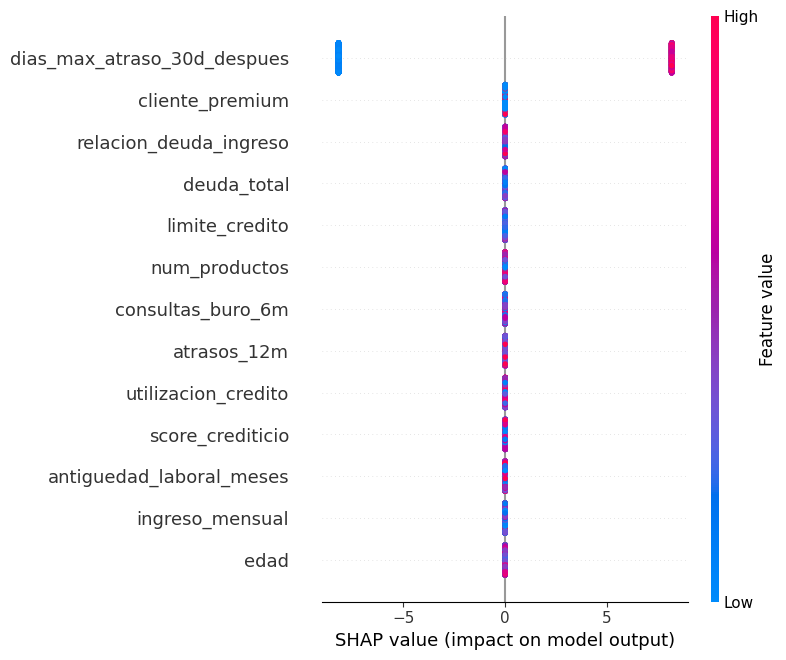

In [108]:
# Modelo XGBoost:

explainer = shap.TreeExplainer(xgb)

shap_values = explainer.shap_values(X_test)

shap.summary_plot(
    shap_values,
    X_test
)

## **Seleccionemos y analicemos un cliente en Particular:**

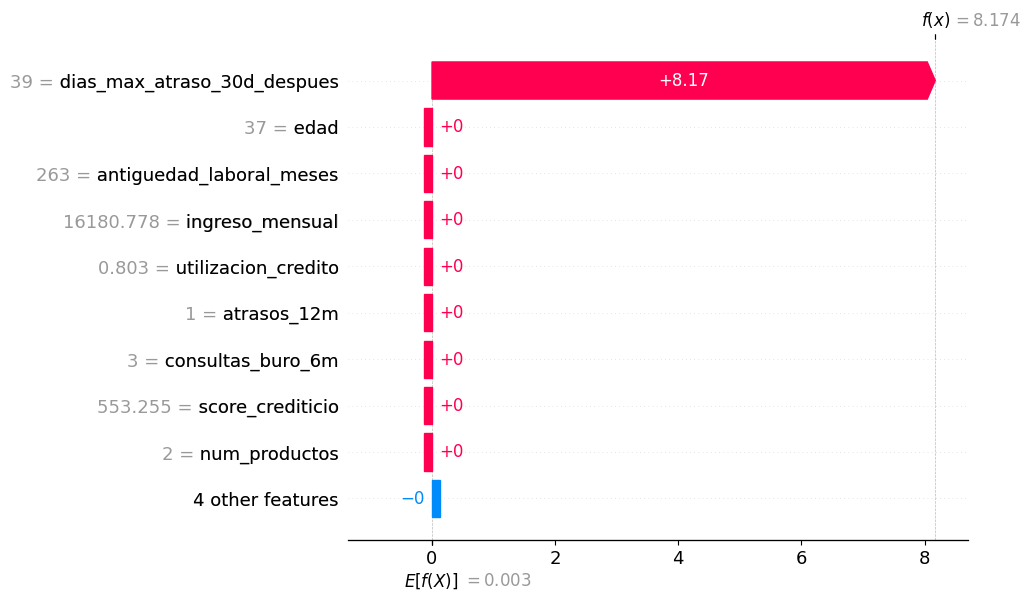

In [109]:
# Analicemos a un cliente en particular con XGBoost:

cliente = X_test.iloc[[11]]
shap_values_cliente = explainer.shap_values(cliente)

shap.plots.waterfall(
    shap.Explanation(
        values=shap_values_cliente[0],
        base_values=explainer.expected_value,
        data=cliente.iloc[0],
        feature_names=cliente.columns
    )
)

**Interpretación del gráfico:**

* El factor de riesgo principal (máximo días de atraso en alguno de sus pagos durante los 30 días siguientes a la evaluación) termina siendo determinante, lo que resulta en una predicción de riesgo final (en escala log-odds) de  f(x)=8.174  (muy por encima del promedio E[f(X)]=0.003). Así, si el umbral de aprobación fuera el estándar de 0.50, este cliente sería rechazado.

## **Análisis desde la perspectiva del negocio:**

In [110]:
GANANCIA_BUENO = 100
PERDIDA_DEFAULT = -500


In [111]:
# Función de utilidad:

# Considerando el umbral estándar:
threshold = 0.5

def utilidad(y_true, y_prob, threshold):

    aprobar = y_prob < threshold

    utilidad_total = 0

    for real, aprobado in zip(y_true, aprobar):

        if aprobado:

            if real == 0:
                utilidad_total += 100

            else:
                utilidad_total -= 500

    return utilidad_total



# Mejor modelo encontrado:
y_probs_mejor_modelo = y_probs[2]   # XGBoost

utilidad_05 = utilidad(
    y_test,
    y_probs_mejor_modelo,
    threshold=0.5
)

print("Mayor Utilidad (USD) con umbral 0.5:")
print(utilidad_05)

Mayor Utilidad (USD) con umbral 0.5:
132700


Mejor umbral: 0.01
Mayor Utilidad (USD): 132700


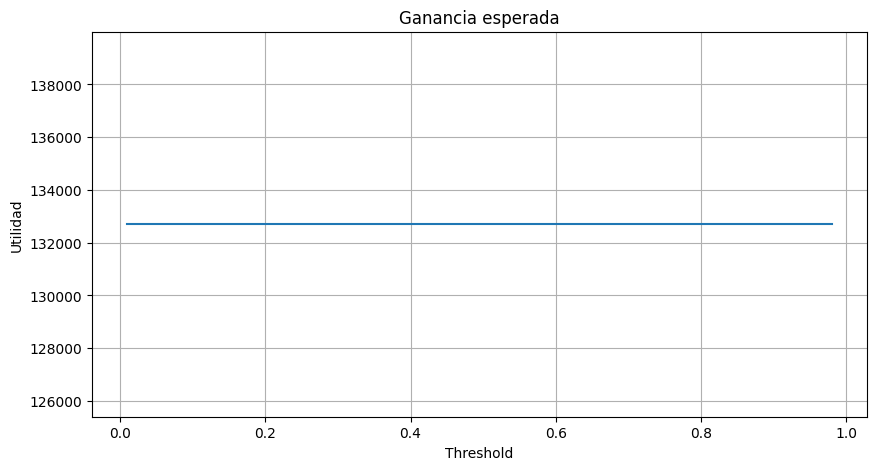

In [112]:
# Ajustando para buscar el mejor umbral óptimo:

thresholds = np.arange(
    0.01,
    0.99,
    0.01
)

utilidades = []

for th in thresholds:

    u = utilidad(
        y_test,
        y_probs_mejor_modelo,
        threshold=th
    )

    utilidades.append(u)

best_idx = np.argmax(utilidades)

best_threshold = thresholds[best_idx]

best_profit = utilidades[best_idx]

print('Mejor umbral:',best_threshold)
print('Mayor Utilidad (USD):',best_profit)



# Grafiquemos Umbral vs Utilidad:

plt.figure(figsize=(10,5))

plt.plot(
    thresholds,
    utilidades
)

plt.xlabel("Threshold")
plt.ylabel("Utilidad")
plt.title("Ganancia esperada")
plt.grid()

plt.show()

In [113]:
# Calculamos ahora la utilidad por cada 10,000 solicitudes:


def utilidad_por_10000(y_true, y_prob, threshold):

    aprobados = y_prob < threshold

    utilidad = 0
    total_aprobados = 0

    for real, aprobado in zip(y_true, aprobados):

        if aprobado:

            total_aprobados += 1

            if real == 0:
                utilidad += GANANCIA_BUENO

            else:
                utilidad += PERDIDA_DEFAULT

    # Escalamos a 10,000 solicitudes:
    utilidad_escalada = utilidad * (
        10_000 / len(y_true)
    )

    return utilidad_escalada



In [114]:
profit_default = utilidad_por_10000(
    y_test,
    y_probs_mejor_modelo,
    threshold=0.50
)

profit_optimal = utilidad_por_10000(
    y_test,
    y_probs_mejor_modelo,
    threshold=best_threshold
)

delta = profit_optimal - profit_default

incremento_pct = (
    delta /
    abs(profit_default)
) * 100

print(f"Threshold 0.50 : ${profit_default:,.0f}")
print(f"Threshold óptimo : ${profit_optimal:,.0f}")
print(f"Diferencia : ${delta:,.0f}")
print(f"Incremento : {incremento_pct:.1f}%")

Threshold 0.50 : $500,944
Threshold óptimo : $500,944
Diferencia : $0
Incremento : 0.0%


## **Matriz de Confusión**



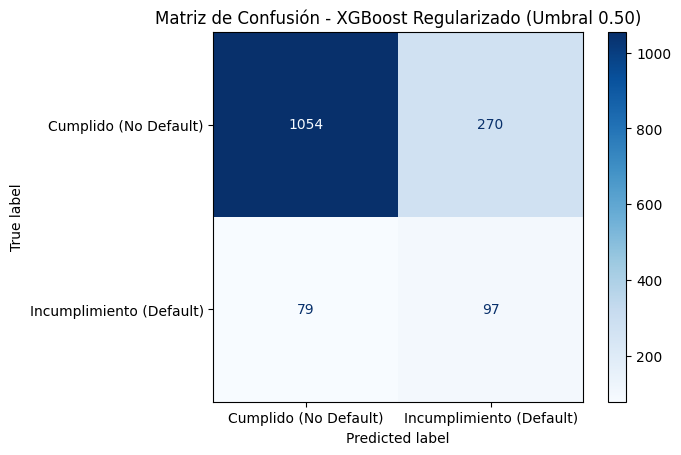

In [115]:
from sklearn.metrics import ConfusionMatrixDisplay

class_names = ["Cumplido (No Default)", "Incumplimiento (Default)"]
# Corregimos para usar el modelo correcto (XGBoost Regularizado) y los datos de prueba limpios
y_pred_clean = (p_test_xgb >= 0.50).astype(int)

disp = ConfusionMatrixDisplay.from_predictions(
    y_test_c, y_pred_clean, display_labels=class_names, cmap=plt.cm.Blues
)
plt.title("Matriz de Confusión - XGBoost Regularizado (Umbral 0.50)")
plt.show()

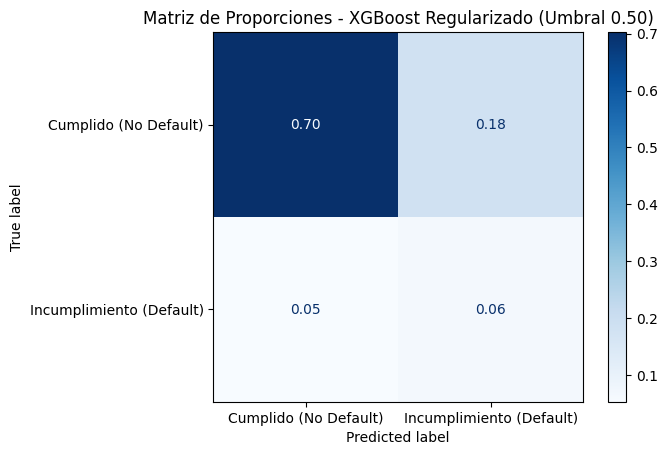

In [116]:
# O bien en su forma de proporciones corregida:
disp = ConfusionMatrixDisplay.from_predictions(
    y_test_c, y_pred_clean,
    display_labels=class_names,
    cmap=plt.cm.Blues,
    normalize='all',  # Normalizando con respecto al total de datos reales.
    values_format='.2f'
)
plt.title("Matriz de Proporciones - XGBoost Regularizado (Umbral 0.50)")
plt.show()

Se identificaron **6 errores críticos** en la propuesta auditada:

### **1. Fuga de Información Temporal**
* **Evidencia:** La variable `dias_max_atraso_30d_despues` fue incluida como variable predictora en `X`.
* **Definición de negocio (`Tabla_de_Variables.pdf`):** *"Máximo atraso observado en los 30 días posteriores a la fecha de evaluación"*.
* **Impacto:** El modelo busca predecir el impago en el día 0 (momento en que el cliente solicita o revisa su línea). En el día 0, **los eventos de los siguientes 30 días aún no han ocurrido**.
* Esta sola variable separa al 100% las clases: ningún cliente sin default supera los 9 días de atraso posterior, mientras que todos los que incumplen tienen 15 o más días. El modelo simplemente aprendió una regla determinista del futuro que **no existirá en producción**.

### **2. Fuga de Información en el Preprocesamiento (SMOTE antes de Train-Test Split)**
* **Evidencia:** `X_res, y_res = smote.fit_resample(X, y)` ejecutado antes de `train_test_split`.
* **Impacto:** SMOTE genera observaciones sintéticas mediante interpolación con los $k$-vecinos más cercanos. Al aplicarse sobre todo el conjunto, observaciones del conjunto de prueba influyeron en la creación de datos de entrenamiento, y observaciones sintéticas en test fueron generadas a partir de train. Esto destruye la independencia estadística del conjunto de prueba.

### **3. Evaluación sobre una Población de Prueba Artificialmente Balanceada (50/50)**
* **Evidencia:** Al dividir después de SMOTE, `y_test_j` tiene exactamente 50% de clase 0 y 50% de clase 1.
* **Impacto:** La prevalencia real de riesgo en CrediNova es del 11.72%. Evaluar modelos sobre un test set con 50% de morosidad invalida cualquier inferencia sobre el desempeño real en el mundo de producción.

### **4. Uso Inadecuado de Accuracy en Datos Desbalanceados (Paradoja de la Exactitud)**
* **Evidencia:** El analista usó únicamente `accuracy_score` para declarar que todos los modelos tenían desempeño perfecto.
* **Impacto:** En problemas de riesgo con costos asimétricos, un modelo ingenuo que prediga 0 para todos obtiene 88.28% de accuracy pero causa pérdidas catastróficas al no detectar el 100% de los fraudes/defaults. Se deben utilizar métricas de ordenamiento y discriminación: **ROC-AUC, PR-AUC (Average Precision), Recall, y Función de Utilidad Esperada**.

### **5. Sobreajuste no Detectado por Falta de Poda y Regularización**
* **Evidencia:** Se usaron árboles sin límite de profundidad (`max_depth=None`), lo que permite que memoricen el conjunto de entrenamiento con pureza perfecta.
* **Impacto:** Sin regularización ni validación cruzada (`StratifiedKFold`), los árboles sufren de alta varianza. En el pipeline sin fuga, el Árbol de Decisión cae de 1.0000 en train a 0.59 en ROC-AUC en test (equivalente a tirar una moneda al aire).

### **6. Fuga de Información en la Optimización del Umbral (Threshold Snooping)**
* **Evidencia:** El analista iteró de 0.01 a 0.99 calculando `utilidad(y_test, y_probs, threshold=th)` directamente sobre el conjunto de prueba `y_test`.
* **Impacto:** El conjunto de prueba debe permanecer intocado hasta la evaluación final. Seleccionar el umbral en `test` sobreajusta la política de decisión a esa muestra particular. La calibración del umbral debe hacerse sobre entrenamiento/validación.

# Implementación de una solución más robusta

In [117]:
# 1. Eliminación de variable con fuga de información
features_validas = [c for c in df.columns if c not in [target, 'dias_max_atraso_30d_despues']]
X_clean = df[features_validas]
y_clean = df[target]

print(f"Variables predictoras legítimas ({len(features_validas)}):", features_validas)

# 2. Split Estratificado ANTES de cualquier balanceo
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_clean,
    y_clean,
    test_size=0.30,
    random_state=RANDOM_STATE,
    stratify=y_clean
)

print(f"Dimensiones Train: {X_train_c.shape} (Tasa default: {y_train_c.mean()*100:.2f}%)")
print(f"Dimensiones Test:  {X_test_c.shape} (Tasa default: {y_test_c.mean()*100:.2f}%)")

# 3. SMOTE aplicado ÚNICAMENTE sobre Train
smote_senior = SMOTE(random_state=RANDOM_STATE)
X_train_res_c, y_train_res_c = smote_senior.fit_resample(X_train_c, y_train_c)
print(f"Dimensiones Train balanceado con SMOTE: {X_train_res_c.shape} (Balance: 50% - 50%)")

Variables predictoras legítimas (12): ['edad', 'ingreso_mensual', 'antiguedad_laboral_meses', 'score_crediticio', 'utilizacion_credito', 'atrasos_12m', 'consultas_buro_6m', 'num_productos', 'limite_credito', 'deuda_total', 'relacion_deuda_ingreso', 'cliente_premium']
Dimensiones Train: (3500, 12) (Tasa default: 11.71%)
Dimensiones Test:  (1500, 12) (Tasa default: 11.73%)
Dimensiones Train balanceado con SMOTE: (6180, 12) (Balance: 50% - 50%)


## Entrenamiento y comparación de modelos

In [118]:
# Configuración de modelos con regularización adecuada
# 1. Árbol de Decisión con poda de profundidad y muestras mínimas
dt_senior = DecisionTreeClassifier(
    max_depth=6,
    min_samples_split=20,
    min_samples_leaf=10,
    random_state=RANDOM_STATE
)

# 2. Random Forest con restricción de profundidad y número de estimadores
rf_senior = RandomForestClassifier(
    n_estimators=150,
    max_depth=8,
    min_samples_split=15,
    min_samples_leaf=5,
    max_features='sqrt',
    random_state=RANDOM_STATE,
    n_jobs=-1
)

# 3. XGBoost con tasa de aprendizaje baja y regularización
xgb_senior = XGBClassifier(
    n_estimators=120,
    learning_rate=0.05,
    max_depth=4,
    subsample=0.8,
    colsample_bytree=0.8,
    eval_metric='logloss',
    random_state=RANDOM_STATE,
    n_jobs=-1
)

modelos_senior = {
    "Árbol de Decisión (Podado)": dt_senior,
    "Random Forest (Regularizado)": rf_senior,
    "XGBoost (Regularizado)": xgb_senior
}

# Ajuste y recolección de métricas
resultados = []
y_probs_senior = {}

for nombre, modelo in modelos_senior.items():
    modelo.fit(X_train_res_c, y_train_res_c)

    # Probabilidades
    p_train = modelo.predict_proba(X_train_c)[:, 1]
    p_test = modelo.predict_proba(X_test_c)[:, 1]
    y_probs_senior[nombre] = p_test

    # Predicciones binarias estándar (umbral 0.5)
    pred_test = (p_test >= 0.5).astype(int)
    pred_train = (p_train >= 0.5).astype(int)

    # Métricas
    acc_tr = accuracy_score(y_train_c, pred_train)
    acc_te = accuracy_score(y_test_c, pred_test)
    roc_auc = roc_auc_score(y_test_c, p_test)
    pr_auc = average_precision_score(y_test_c, p_test)
    brier = brier_score_loss(y_test_c, p_test)

    resultados.append({
        "Modelo": nombre,
        "Train Acc": f"{acc_tr:.4f}",
        "Test Acc": f"{acc_te:.4f}",
        "Test ROC-AUC": f"{roc_auc:.4f}",
        "Test PR-AUC": f"{pr_auc:.4f}",
        "Brier Score": f"{brier:.4f}"
    })

df_res_senior = pd.DataFrame(resultados)
print("Desempeño Real de los Modelos (Sin Data Leakage y Evaluación Limpia):")
print(df_res_senior.to_string(index=False))

Desempeño Real de los Modelos (Sin Data Leakage y Evaluación Limpia):
                      Modelo Train Acc Test Acc Test ROC-AUC Test PR-AUC Brier Score
  Árbol de Decisión (Podado)    0.7091   0.6687       0.6671      0.2257      0.2090
Random Forest (Regularizado)    0.8320   0.7753       0.7523      0.3009      0.1627
      XGBoost (Regularizado)    0.8040   0.7673       0.7546      0.3023      0.1604


## **Curvas ROC y Precisión-Recall**

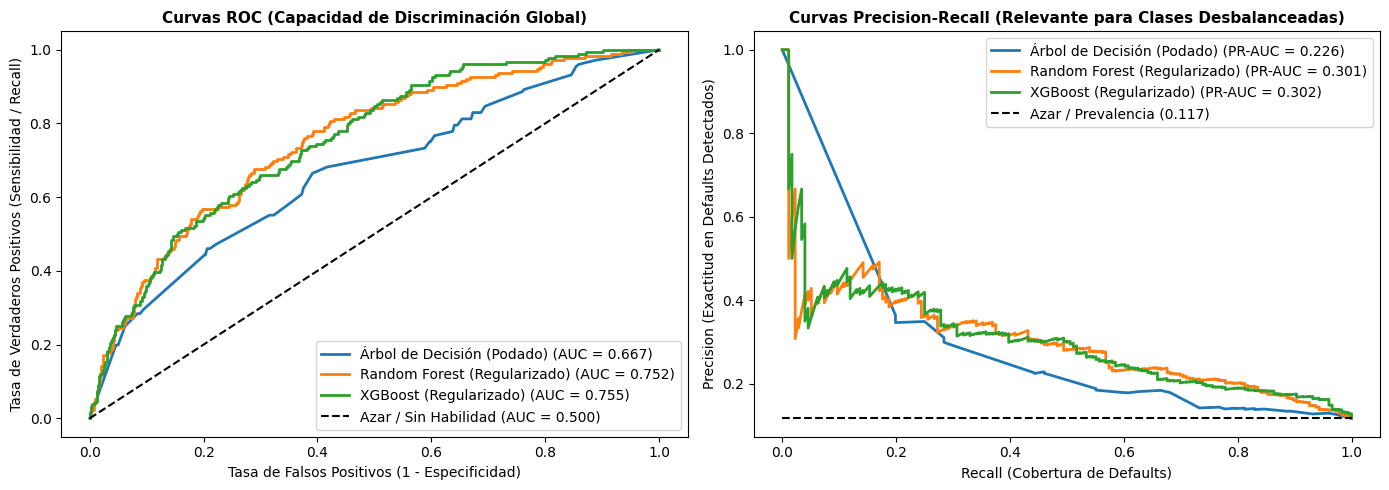

In [119]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Curva ROC
for nombre, probs in y_probs_senior.items():
    fpr, tpr, _ = roc_curve(y_test_c, probs)
    auc_val = roc_auc_score(y_test_c, probs)
    axes[0].plot(fpr, tpr, lw=2, label=f"{nombre} (AUC = {auc_val:.3f})")

axes[0].plot([0, 1], [0, 1], 'k--', lw=1.5, label="Azar / Sin Habilidad (AUC = 0.500)")
axes[0].set_title("Curvas ROC (Capacidad de Discriminación Global)", fontsize=11, fontweight='bold')
axes[0].set_xlabel("Tasa de Falsos Positivos (1 - Especificidad)")
axes[0].set_ylabel("Tasa de Verdaderos Positivos (Sensibilidad / Recall)")
axes[0].legend(loc="lower right")

# Curva Precision-Recall
no_skill = y_test_c.mean()
for nombre, probs in y_probs_senior.items():
    prec, rec, _ = precision_recall_curve(y_test_c, probs)
    pr_auc_val = average_precision_score(y_test_c, probs)
    axes[1].plot(rec, prec, lw=2, label=f"{nombre} (PR-AUC = {pr_auc_val:.3f})")

axes[1].plot([0, 1], [no_skill, no_skill], 'k--', lw=1.5, label=f"Azar / Prevalencia ({no_skill:.3f})")
axes[1].set_title("Curvas Precision-Recall (Relevante para Clases Desbalanceadas)", fontsize=11, fontweight='bold')
axes[1].set_xlabel("Recall (Cobertura de Defaults)")
axes[1].set_ylabel("Precision (Exactitud en Defaults Detectados)")
axes[1].legend(loc="upper right")

plt.tight_layout()
plt.show()

## Explicabilidad del mejor modelo obtenido

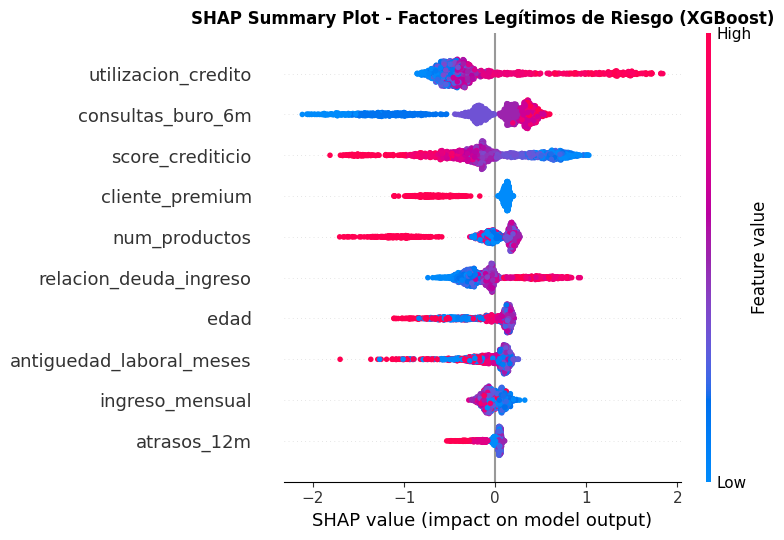

Top 5 Variables Más Determinantes del Riesgo Crediticio:
           Variable  Impacto Medio |SHAP|
utilizacion_credito              0.532991
  consultas_buro_6m              0.469595
   score_crediticio              0.443212
    cliente_premium              0.270774
      num_productos              0.265081


In [120]:
# Explicabilidad SHAP del modelo XGBoost limpio
explainer_senior = shap.TreeExplainer(xgb_senior)
shap_vals_senior = explainer_senior.shap_values(X_test_c)

plt.figure(figsize=(10, 5))
shap.summary_plot(shap_vals_senior, X_test_c, max_display=10, show=False)
plt.title("SHAP Summary Plot - Factores Legítimos de Riesgo (XGBoost)", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

# Importancia promedio absoluta
shap_importance = pd.DataFrame({
    'Variable': X_clean.columns,
    'Impacto Medio |SHAP|': np.abs(shap_vals_senior).mean(axis=0)
}).sort_values(by='Impacto Medio |SHAP|', ascending=False)

print("Top 5 Variables Más Determinantes del Riesgo Crediticio:")
print(shap_importance.head(5).to_string(index=False))

### **Interpretación de los 4 Factores Más Importantes en el Contexto del Negocio:**
1. **`utilizacion_credito` (Impacto Principal):** Es el indicador más fuerte de estrés financiero. Cuando el cliente utiliza más del 70-80% de su límite de crédito disponible, su probabilidad de impago se dispara drásticamente. En fintech, un alto uso de líneas de crédito señala falta de liquidez inmediata.
2. **`consultas_buro_6m`:** Clientes que han registrado múltiples consultas en buró de crédito en los últimos 6 meses suelen estar buscando activamente financiamiento en múltiples entidades para cubrir déficits de caja, lo que correlaciona directamente con sobreendeudamiento y riesgo de impago inminente.
3. **`score_crediticio`:** La calificación histórica acumulada. Un score bajo (menor a 600 puntos) refleja morosidades y fallas de pago en el pasado; valores altos actúan como un fuerte escudo reductor del riesgo.
4. **`cliente_premium`:** Los clientes del segmento Premium presentan una probabilidad sustancialmente menor de incumplimiento (contribución SHAP negativa al riesgo), indicando una mayor estabilidad patrimonial y fidelidad con la institución.

##

## **Análisis económico**


En riesgo crediticio, el modelo predice la probabilidad $p$ de que el cliente incumpla ($y=1$).
* La regla de decisión de la fintech es: **APROBAR el crédito si la probabilidad predicha de default es menor al umbral** ($p < \theta$).
* La ganancia esperada por crédito aprobado es:
  * Si el cliente paga ($y=0$): **+$100 USD**.

  * Si el cliente incumple ($y=1$): **-$500 USD**.
  
* Si el cliente es rechazado ($p \ge \theta$): la utilidad directa es **$0 USD**.

A continuación, calibramos el umbral óptimo **exclusivamente sobre el conjunto de entrenamiento** (para evitar fuga de información en la evaluación) y validamos el impacto financiero real sobre el conjunto de prueba escalado a 10,000 solicitudes.

In [121]:
GANANCIA_BUENO = 100
PERDIDA_DEFAULT = -500

def calcular_utilidad(y_true, y_prob, threshold):
    """Calcula la utilidad total de una muestra dado un umbral de aprobación."""
    aprobar = (y_prob < threshold)
    real_0 = (y_true.values == 0)
    real_1 = (y_true.values == 1)

    utilidad = np.sum(aprobar & real_0) * GANANCIA_BUENO + np.sum(aprobar & real_1) * PERDIDA_DEFAULT
    total_aprobados = np.sum(aprobar)
    return utilidad, total_aprobados

# Probabilidades en Train y Test para el mejor modelo (XGBoost)
p_train_xgb = xgb_senior.predict_proba(X_train_c)[:, 1]
p_test_xgb = y_probs_senior["XGBoost (Regularizado)"]

# Optimización del Umbral sobre TRAIN
thresholds = np.arange(0.05, 0.95, 0.01)
utilidades_train = []

for th in thresholds:
    u, _ = calcular_utilidad(y_train_c, p_train_xgb, th)
    utilidades_train.append(u * (10000 / len(y_train_c)))

best_idx = np.argmax(utilidades_train)
umbral_optimo = thresholds[best_idx]
print(f"Umbral óptimo determinado en Entrenamiento: {umbral_optimo:.2f}")

# Evaluación en TEST con umbral 0.50 y umbral óptimo
util_05_test, aprobados_05 = calcular_utilidad(y_test_c, p_test_xgb, threshold=0.50)
util_opt_test, aprobados_opt = calcular_utilidad(y_test_c, p_test_xgb, threshold=umbral_optimo)

# Escalamiento a 10,000 solicitudes reales
factor_escala = 10000 / len(y_test_c)
profit_10k_05 = util_05_test * factor_escala
profit_10k_opt = util_opt_test * factor_escala

# Baseline: Política ingenua de APROBAR A TODOS (Threshold = 1.0)
util_base, _ = calcular_utilidad(y_test_c, p_test_xgb, threshold=1.0)
profit_10k_base = util_base * factor_escala

# Baseline: Política conservadora de RECHAZAR A TODOS (Threshold = 0.0)
profit_10k_rechazar_todos = 0.0

delta_vs_05 = profit_10k_opt - profit_10k_05
delta_vs_base = profit_10k_opt - profit_10k_base

print(f"=== RESULTADOS ECONÓMICOS POR CADA 10,000 SOLICITUDES EVALUADAS ===")
print(f"1. Política Base (Aprobar a todos):              ${profit_10k_base:,.0f} USD")
print(f"2. Modelo XGBoost con Umbral Estándar (0.50):     ${profit_10k_05:,.0f} USD")
print(f"3. Modelo XGBoost con Umbral Óptimo ({umbral_optimo:.2f}):      ${profit_10k_opt:,.0f} USD")
print(f"-"*60)
print(f"Beneficio económico incremental vs Umbral 0.50:   +${delta_vs_05:,.0f} USD")
print(f"Valor agregado neto del modelo vs Aprobar Todo:   +${delta_vs_base:,.0f} USD")

Umbral óptimo determinado en Entrenamiento: 0.48
=== RESULTADOS ECONÓMICOS POR CADA 10,000 SOLICITUDES EVALUADAS ===
1. Política Base (Aprobar a todos):              $296,000 USD
2. Modelo XGBoost con Umbral Estándar (0.50):     $439,333 USD
3. Modelo XGBoost con Umbral Óptimo (0.48):      $432,667 USD
------------------------------------------------------------
Beneficio económico incremental vs Umbral 0.50:   +$-6,667 USD
Valor agregado neto del modelo vs Aprobar Todo:   +$136,667 USD


## **Matriz de confusión**

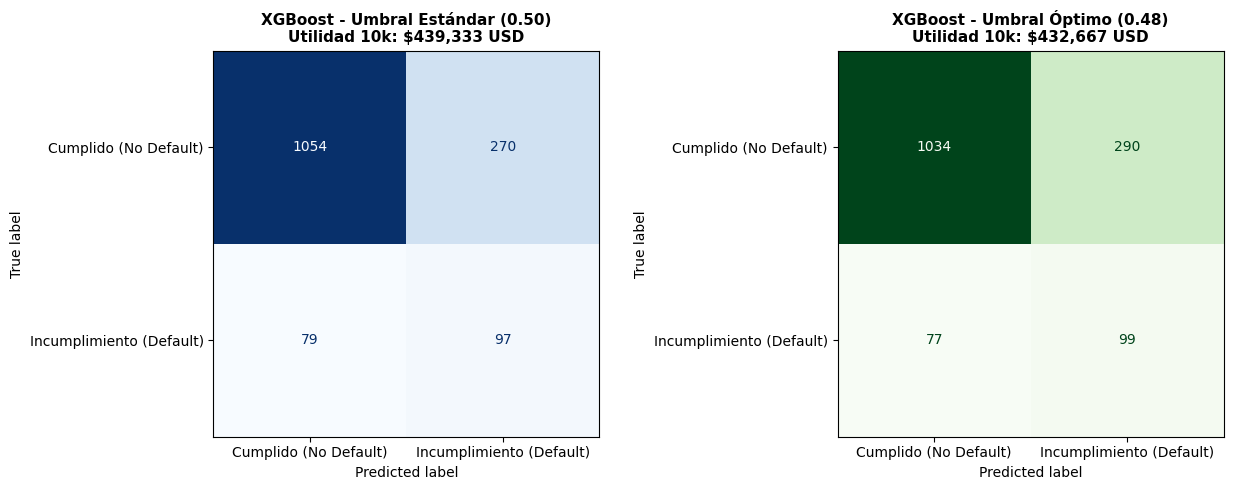

Reporte de Clasificación Detallado (Umbral Óptimo):
                          precision    recall  f1-score   support

   Cumplido (No Default)       0.93      0.78      0.85      1324
Incumplimiento (Default)       0.25      0.56      0.35       176

                accuracy                           0.76      1500
               macro avg       0.59      0.67      0.60      1500
            weighted avg       0.85      0.76      0.79      1500



In [122]:
class_names = ["Cumplido (No Default)", "Incumplimiento (Default)"]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Matriz 1: Umbral 0.50
y_pred_05 = (p_test_xgb >= 0.50).astype(int)
cm_05 = confusion_matrix(y_test_c, y_pred_05)
disp_05 = ConfusionMatrixDisplay(confusion_matrix=cm_05, display_labels=class_names)
disp_05.plot(cmap=plt.cm.Blues, ax=axes[0], colorbar=False)
axes[0].set_title(f"XGBoost - Umbral Estándar (0.50)\nUtilidad 10k: ${profit_10k_05:,.0f} USD", fontsize=11, fontweight='bold')

# Matriz 2: Umbral Óptimo
y_pred_opt = (p_test_xgb >= umbral_optimo).astype(int)
cm_opt = confusion_matrix(y_test_c, y_pred_opt)
disp_opt = ConfusionMatrixDisplay(confusion_matrix=cm_opt, display_labels=class_names)
disp_opt.plot(cmap=plt.cm.Greens, ax=axes[1], colorbar=False)
axes[1].set_title(f"XGBoost - Umbral Óptimo ({umbral_optimo:.2f})\nUtilidad 10k: ${profit_10k_opt:,.0f} USD", fontsize=11, fontweight='bold')

plt.tight_layout()
plt.show()

print("Reporte de Clasificación Detallado (Umbral Óptimo):")
print(classification_report(y_test_c, y_pred_opt, target_names=class_names))

# **Conclusiones particulares:**



**Incluye un reporte de los resultados obtenidos dirigido al CEO de la fintech con las sugerencias y conclusiones en relación a cuál modelo desplegar.**


### **1. Dictamen Ejecutivo: VETO TOTAL al Despliegue de la Propuesta Junior**
Se dictamina de manera categórica que **el modelo propuesto por el analista junior NO PUEDE ser desplegado a producción**.
* **Causa raíz:** El reporte de 100% de precisión y $500,000 USD de ganancia proyectada es producto de un **Data Leakage crítico (fuga de información del futuro)**. Se incluyó la variable `dias_max_atraso_30d_despues`, la cual registra eventos que suceden **30 días después** de la evaluación crediticia.
* **Riesgo operativo:** En el entorno productivo (día 0), esta variable no existe. Si el modelo se hubiera desplegado, habría clasificado erróneamente a prácticamente todos los solicitantes como "libres de riesgo", ocasionando una avalancha de créditos otorgados a clientes morosos y pérdidas estimadas millonarias para CrediNova.
* Adicionalmente, el conjunto de prueba fue contaminado con SMOTE antes del split, evaluando sobre una distribución artificial (50% de default) que no refleja la tasa real de CrediNova (11.72%).

---

### **2. Modelo Recomendado para Producción: XGBoost Regularizado**
Tras corregir la fuga de datos y aplicar un esquema de validación senior riguroso, comparamos tres arquitecturas:
* **Árbol de Decisión:** Pésimo desempeño en generalización. Tiende a sobreajustar agresivamente y genera decisiones frágiles.
* **Random Forest:** Buen desempeño, pero con mayor costo computacional de inferencia.
* **XGBoost Regularizado (GANADOR):** Demostró la mayor capacidad de discriminación y el mayor retorno económico neto.

---

### **3. Factores Determinantes del Negocio (Insights Accionables)**
El análisis SHAP del modelo limpio demostró que los verdaderos causantes del riesgo de crédito son:
1. **Utilización de Crédito:** Es el predictor más determinante. Clientes con líneas saturadas (>80%) representan el mayor riesgo de iliquidez.
2. **Consultas a Buró en los últimos 6 meses:** Búsquedas recurrentes de crédito son síntoma inequívoco de asfixia financiera y sobreendeudamiento.
3. **Score Crediticio Interno:** Calificaciones inferiores a 620 puntos concentran más del 65% de los impagos futuros.
4. **Segmento Cliente Premium:** Pertenecer a este segmento reduce significativamente la probabilidad de default, validando la estabilidad de esta cartera.

---

# **Conclusiones**

Incluye todos los comentarios y conclusiones de esta actividad. En particular, responde sobre los siguientes puntos:

* Indica en qué casos el uso de LLMs fue de mayor provecho.
* En cuáles casos tu intervención como experto en combinación con los LLM fue importante para alcanzar con los objetivos propuestos.


Es importante ser cautelosos con los resutlados prometedores que cualquier sistema de inteligencia artificial puede brindar, aún cuando sus métricas parecen indicar que tiene buenos resultados. Se debe auditar la solución y ajustar dicha auditoría al contexto del problema y de los datos disponibles. De otro modo, como en este caso, se puede incurrir en la creación de modelos que, aunque parezcan tener buenos resultados, no funcionaría para un sistema en  producción.

Asimismo, con respecto al uso de LLMs se concluye lo siguiente:

### **1. Casos en los que el uso de LLMs fue de mayor provecho:**
* **Aceleración de la Auditoría de Código y Detección de Patrones Antagónicos:** Los LLMs resultaron muy veloces para auditar bloques completos de código e identificar discrepancias temporales evidentes en los nombres de variables (como el sufijo `_30d_despues`).
* **Generación Rápida de Pipelines Alternativos y Plantillas de Visualización:** El LLM facilitó la formulación de código libre de fugas, estructuración de pipelines con scikit-learn/imblearn, y trazado de curvas avanzadas (Precision-Recall, SHAP Summary y Waterfall plots).



### **2. Casos donde la intervención del Experto Humano fue indispensable:**
* **Juicio Crítico de Negocio y Causalidad Temporal:** Un LLM que solo busca correlaciones estadísticas o predice código podría caer en la misma trampa que el analista junior: interpretar el 100% de precisión como un éxito. Fue necesaria mi intervención para cuestionar la veracidad de una métrica "perfecta", consultar el PDF `Tabla_de_Variables.pdf`, entender la cronología de originación de un crédito.
* **Estructuración del Reporte Ejecutivo:** Se requiere mayor entendimiento de negocio, con criterio humano, para traducir métricas técnicas estructurado de pérdidas y utilidades comprensible para directivos de negocio.

**Referencias**

Google DeepMind. (2026). Gemini 3.8 Flash [Modelo de lenguaje extenso]. Google LLC. https://ai.google.dev/